In [1]:
import re
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

RAW_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/data/raw")                     # raw Car Scanner exports (never modified)
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage1_inventory")     # all Stage 1 results go here
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Thresholds used to flag problems (documented in one place)
CFG = {
    "max_valid_speed_kmh": 250,      # BYD Atto 3 cannot exceed this; 255 = 0xFF decode error
    "moving_speed_kmh": 5,           # above this the car is treated as moving
    "row_gap_s": 60,                 # no rows at all for longer than this = logging gap
    "obd_gap_s": 12,                 # no OBD data for longer than this (GPS still logging) = OBD dropout
    "gps_frozen_s": 30,              # GPS position unchanged this long while moving = GPS freeze
    "gps_jump_m": 25,                # fix this far from its neighbours' median track = GPS jump
    "sri_lanka_lat": (5.9, 9.9),     # bounding box for valid coordinates
    "sri_lanka_lon": (79.5, 82.0),
}
COLORS = {"Route A": "#2a78d6", "Route B": "#eb6834", "bar": "#2a78d6"}

In [2]:
def find_raw_files(raw_dir):
    """All Car Scanner CSV exports under raw_dir, with the trip date/time read from the file name."""
    rows = []
    for f in sorted(raw_dir.rglob("*.csv")):
        m = re.search(r"(\d{4}-\d{2}-\d{2})[ _](\d{2}-\d{2}-\d{2})", f.name)
        if not m:                                   # not a Car Scanner export (e.g. a notes file)
            continue
        rows.append({"file": f.name, "path": f,
                     "file_datetime": pd.to_datetime(m.group(1) + " " + m.group(2),
                                                     format="%Y-%m-%d %H-%M-%S")})
    files = pd.DataFrame(rows).sort_values("file_datetime").reset_index(drop=True)
    files.insert(0, "trip_id", [f"T{i:03d}" for i in range(1, len(files) + 1)])
    return files

files = find_raw_files(RAW_DIR)
print(f"{len(files)} raw files found in {RAW_DIR}")
display(files[["trip_id", "file", "file_datetime"]].head(10))

77 raw files found in /content/drive/MyDrive/Colab Notebooks/Component01/data/raw


,trip_id,file,file_datetime
0,T001,2026-08-03_07-00-44.csv,2026-08-03 07:00:44
1,T002,2026-08-03_18-13-32.csv,2026-08-03 18:13:32
2,T003,2026-08-03_19-54-03.csv,2026-08-03 19:54:03
3,T004,2026-08-03_22-20-23.csv,2026-08-03 22:20:23
4,T005,2026-08-04_08-40-32.csv,2026-08-04 08:40:32
5,T006,2026-08-05_11-54-41.csv,2026-08-05 11:54:41
6,T007,2026-08-05_20-25-26.csv,2026-08-05 20:25:26
7,T008,2026-08-09_20-05-26.csv,2026-08-09 20:05:26
8,T009,2026-08-10_07-59-00.csv,2026-08-10 07:59:00
9,T010,2026-08-10_13-31-23.csv,2026-08-10 13:31:23


In [3]:
def load_carscanner(path):
    """Read one Car Scanner CSV. Returns the rows plus 'timestamp' and 't_s' (seconds from log start)."""
    path = Path(path)

    # 1) header – make duplicated column names unique ("name #2")
    with open(path, encoding="utf-8") as f:
        header = next(csv.reader(f))
    names, seen = [], {}
    for h in header:
        h = h.strip() or "_empty"
        seen[h] = seen.get(h, 0) + 1
        names.append(h if seen[h] == 1 else f"{h} #{seen[h]}")

    # 2) values – everything except 'time' becomes numeric (empty cell -> NaN)
    df = pd.read_csv(path, header=None, skiprows=1, names=names, dtype=str)
    df = df.drop(columns=["_empty"], errors="ignore")
    value_cols = [c for c in df.columns if c != "time"]
    df[value_cols] = df[value_cols].apply(pd.to_numeric, errors="coerce")

    # 3) timestamps – date from the file name, clock time from the 'time' column
    date = re.search(r"\d{4}-\d{2}-\d{2}", path.name).group(0)
    ts = pd.to_datetime(date + " " + df["time"], format="%Y-%m-%d %H:%M:%S.%f")
    ts = ts + pd.to_timedelta((ts.diff().dt.total_seconds() < -43200).cumsum(), unit="D")  # past midnight
    df.insert(0, "timestamp", ts)
    df.insert(1, "t_s", (ts - ts.iloc[0]).dt.total_seconds())
    return df

example = load_carscanner(files.loc[0, "path"])
print(files.loc[0, "file"], "->", example.shape[0], "rows x", example.shape[1], "columns")
display(example.head(100))

2026-08-03_07-00-44.csv -> 6924 rows x 54 columns


,timestamp,t_s,time,[BASU] Battery total current (A),[BASU] Battery total voltage (V),[BASU] Highest temperature cell value (℃),[BASU] Highest voltage cell value (V),[BASU] HV Battery Pack Current Nominal Capacity (Ah),[BASU] HV Battery Pack Current Nominal SoC (%),[BASU] HV Battery Pack Factory Capacity (Ah),[BASU] HV Battery Pack Factory SoC (%),[BASU] Lowest temperature cell value (℃),[BASU] Lowest voltage cell value (V),[BASU] Maximum allowed charge power (kW),[BASU] Maximum allowed discharge power (kW),[BASU] Pack 1 highest temperature cell value (℃),[BASU] Pack 1 lowest temperature cell number (),[BASU] Pack 1 lowest temperature cell value (℃),[BASU] Pack 1 Lowest voltage cell value (V),[BASU] Pack 6 lowest temperature cell number (),[BASU] Pack 6 lowest temperature cell value (℃),[BASU] Pack 6 Lowest voltage cell value (V),[BASU] Times off full power [second-rate] (),[MMCU] Main Drive motor Power (kW),[MMCU] Main Drive motor RPM (rpm),[MMCU] Main Drive motor Temperature (℃),[MMCU] Main Drive motor Torque (N⋅m),[PDC] Vehicle operation mode (),[PDC] Vehicle speed (km/h),[PDC] Vehicle speed (km/h) #2,[PDC] Water temperature (℃),Altitude (GPS) (m),Average speed (km/h),Average speed (GPS) (km/h),Battery SOH (calculated) (%),Battery SOH (calculated) (%) #2,Cell voltage delta (mV),Cell voltage delta (mV) #2,Distance travelled (km),Distance travelled (Today) (km),Distance travelled (total) (km),Distance travelled (Week) (km),Energy costs ($),Energy used (kWh),EV Instant Energy Consumption (distance/kWh) (km/kWh),EV Instant Energy Consumption (kWh) (kWh),EV Instant Energy Consumption (kWh/distance) (kWh/100km),HV EV Battery Power (kW),Motor speed v.2 (rpm),Motor torque v.2 (N⋅m),Speed (GPS) (km/h),Vehicle acceleration (g),Latitude,Longtitude
0,2026-08-03 07:00:44.520,0.000,07:00:44.520,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-03 07:01:06.335,21.815,07:01:06.335,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002640,79.953397
2,2026-08-03 07:01:06.625,22.105,07:01:06.625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002640,79.953397
3,2026-08-03 07:01:06.892,22.372,07:01:06.892,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002640,79.953397
4,2026-08-03 07:01:07.120,22.600,07:01:07.120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002640,79.953397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2026-08-03 07:01:30.309,45.789,07:01:30.309,NaN,NaN,NaN,NaN,NaN,NaN,152.0,66.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.0,98.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002646,79.953397
96,2026-08-03 07:01:30.498,45.978,07:01:30.498,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.002646,79.953397
97,2026-08-03 07:01:31.760,47.240,07:01:31.760,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,284.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

In [4]:
COL = {
    "speed":     "[PDC] Vehicle speed (km/h)",
    "voltage":   "[BASU] Battery total voltage (V)",
    "current":   "[BASU] Battery total current (A)",
    "cell_low":  "[BASU] Lowest voltage cell value (V)",
    "soc":       "[BASU] HV Battery Pack Current Nominal SoC (%)",
    "power":     "HV EV Battery Power (kW)",
    "energy":    "Energy used (kWh)",
    "distance":  "Distance travelled (km)",
    "gps_speed": "Speed (GPS) (km/h)",
    "lat":       "Latitude",
    "lon":       "Longtitude",                 # spelling used by Car Scanner
}
OBD_COLS = [c for c in example.columns if c.startswith("[")]
APP_COLS = [c for c in example.columns if c not in OBD_COLS and c not in ("timestamp", "t_s", "time")]
print(len(OBD_COLS), "OBD-II columns,", len(APP_COLS), "phone / app-calculated columns")

28 OBD-II columns, 23 phone / app-calculated columns


In [5]:
def haversine_m(lat1, lon1, lat2, lon2):
    """Distance in metres between two GPS points."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371000 * np.arcsin(np.sqrt(a))


def gps_fixes(df):
    """Rows where the GPS position changed = new GPS fixes."""
    g = df.loc[df[COL["lat"]].notna(), ["t_s", COL["lat"], COL["lon"]]]
    return g[(g[COL["lat"]].diff() != 0) | (g[COL["lon"]].diff() != 0)]


def inventory_one(df):
    """Inventory measures for one loaded file."""
    t = df["t_s"]
    r = {}

    # --- time span
    r["start"] = df["timestamp"].iloc[0]
    r["end"] = df["timestamp"].iloc[-1]
    r["duration_min"] = round(t.iloc[-1] / 60, 1)
    r["n_rows"] = len(df)

    # --- sampling
    spd = df.loc[df[COL["speed"]].notna(), ["t_s", COL["speed"]]]
    fixes = gps_fixes(df)
    r["n_speed_readings"] = len(spd)
    r["speed_interval_s"] = round(spd["t_s"].diff().median(), 2)
    r["n_gps_fixes"] = len(fixes)
    r["gps_interval_s"] = round(fixes["t_s"].diff().median(), 2)

    # --- missing data / gaps
    r["max_row_gap_s"] = round(t.diff().max(), 1)
    obd_t = t[df[OBD_COLS].notna().any(axis=1)].values
    r["n_obd_dropouts"] = sum(
        1 for a, b in zip(obd_t[:-1], obd_t[1:])
        if b - a > CFG["obd_gap_s"] and ((t > a) & (t < b)).sum() >= (b - a) / 2   # other rows kept coming
    )

    # --- GPS frozen while moving
    speed_ff = df[COL["speed"]].where(df[COL["speed"]] < CFG["max_valid_speed_kmh"]).ffill()
    idx = fixes.index.values
    unchanged_s = np.r_[np.diff(fixes["t_s"].values), t.iloc[-1] - fixes["t_s"].values[-1]]
    rows_after = np.diff(np.r_[idx, len(df)])
    frozen = (speed_ff.loc[idx].values > CFG["moving_speed_kmh"]) & (rows_after >= unchanged_s / 2)
    r["max_gps_frozen_s"] = round(unchanged_s[frozen].max(), 1) if frozen.any() else 0.0

    # --- GPS jumps (fix far from the median track of its 10 neighbours)
    med_lat = fixes[COL["lat"]].rolling(11, center=True, min_periods=5).median()
    med_lon = fixes[COL["lon"]].rolling(11, center=True, min_periods=5).median()
    dev = haversine_m(med_lat, med_lon, fixes[COL["lat"]], fixes[COL["lon"]])
    window_s = fixes["t_s"].shift(-5) - fixes["t_s"].shift(5)
    r["n_gps_jumps"] = int(((dev > CFG["gps_jump_m"]) & (window_s <= 15)).sum())

    # --- duplicates and invalid values
    r["n_duplicate_rows"] = int(df.drop(columns=["timestamp", "t_s"]).duplicated().sum())
    r["n_invalid_values"] = int(
        (df[COL["speed"]] > CFG["max_valid_speed_kmh"]).sum()
        + (df[COL["voltage"]] == 0).sum()
        + (df[COL["current"]] <= -999).sum()
        + (df[COL["cell_low"]] == 0).sum()
    )
    g = df[[COL["lat"], COL["lon"]]].dropna()
    r["n_coords_outside_SL"] = int((~g[COL["lat"]].between(*CFG["sri_lanka_lat"])
                                    | ~g[COL["lon"]].between(*CFG["sri_lanka_lon"])).sum())

    # --- trip summary (valid speeds only)
    valid = spd.loc[spd[COL["speed"]] < CFG["max_valid_speed_kmh"], COL["speed"]]
    soc = df[COL["soc"]].dropna()
    r["max_speed_kmh"] = valid.max()
    r["distance_km"] = round(df[COL["distance"]].max(), 2)
    r["energy_kwh"] = round(df[COL["energy"]].dropna().iloc[-1], 2) if df[COL["energy"]].notna().any() else np.nan
    r["soc_start"] = soc.iloc[0] if len(soc) else np.nan
    r["soc_end"] = soc.iloc[-1] if len(soc) else np.nan
    r["starts_moving"] = bool(len(valid) and valid.iloc[0] > CFG["moving_speed_kmh"])
    r["ends_moving"] = bool(len(valid) and valid.iloc[-1] > CFG["moving_speed_kmh"])

    # --- route hint from GPS position only (NOT an environment label – that is Stage 5)
    lon_med = g[COL["lon"]].median()
    r["route_hint"] = "Route B" if lon_med > 79.94 else "Route A"
    r["median_lon"] = round(lon_med, 4)
    r["time_over_80kmh_%"] = round((valid > 80).mean() * 100, 1) if len(valid) else 0.0
    return r


def parameter_availability(df):
    """For every OBD / app column: number of readings and typical interval between readings."""
    out = {}
    for c in OBD_COLS + APP_COLS:
        tt = df.loc[df[c].notna(), "t_s"]
        out[c] = {"readings": len(tt), "interval_s": tt.diff().median() if len(tt) > 1 else np.nan}
    return out

In [6]:
inv_rows, avail_rows = [], []

for i, row in files.iterrows():
    df = load_carscanner(row["path"])
    inv_rows.append({"trip_id": row["trip_id"], "file": row["file"], **inventory_one(df)})
    for col, v in parameter_availability(df).items():
        avail_rows.append({"trip_id": row["trip_id"], "parameter": col, **v})
    if (i + 1) % 10 == 0 or i + 1 == len(files):
        print(f"{i + 1}/{len(files)} files processed")

inventory = pd.DataFrame(inv_rows)
availability = pd.DataFrame(avail_rows)

inventory.to_csv(OUT_DIR / "inventory.csv", index=False)
inventory.head(10)

10/77 files processed
20/77 files processed
30/77 files processed
40/77 files processed
50/77 files processed
60/77 files processed
70/77 files processed
77/77 files processed


,trip_id,file,start,end,duration_min,n_rows,n_speed_readings,speed_interval_s,n_gps_fixes,gps_interval_s,max_row_gap_s,n_obd_dropouts,max_gps_frozen_s,n_gps_jumps,n_duplicate_rows,n_invalid_values,n_coords_outside_SL,max_speed_kmh,distance_km,energy_kwh,soc_start,soc_end,starts_moving,ends_moving,route_hint,median_lon,time_over_80kmh_%
0,T001,2026-08-03_07-00-44.csv,2026-08-03 07:00:44.520,2026-08-03 07:32:03.692,31.3,6924,471,3.69,1841,1.0,21.8,1,3.4,0,0,0,0,91.0,35.63,5.45,88.0,79.0,False,False,Route B,79.9801,72.2
1,T002,2026-08-03_18-13-32.csv,2026-08-03 18:13:32.365,2026-08-03 18:42:29.819,29.0,6584,452,3.71,1700,1.0,21.3,0,3.6,0,0,0,0,100.7,35.57,5.84,79.0,69.7,False,False,Route B,79.9796,74.6
2,T003,2026-08-03_19-54-03.csv,2026-08-03 19:54:03.799,2026-08-03 20:29:16.808,35.2,7979,550,3.70,2064,1.0,20.8,0,3.7,0,0,0,0,52.6,19.06,2.66,69.7,65.5,False,False,Route A,79.8872,0.0
3,T004,2026-08-03_22-20-23.csv,2026-08-03 22:20:23.811,2026-08-03 23:00:37.519,40.2,9132,630,3.71,2361,1.0,18.8,0,3.9,6,0,0,0,52.6,19.06,2.52,65.5,61.4,False,False,Route A,79.8878,0.0
4,T005,2026-08-04_08-40-32.csv,2026-08-04 08:40:32.774,2026-08-04 09:12:02.095,31.5,7052,486,3.69,1835,1.0,19.7,0,4.1,4,0,0,0,93.6,35.66,5.46,61.4,52.6,False,False,Route B,79.9798,70.8
5,T006,2026-08-05_11-54-41.csv,2026-08-05 11:54:41.933,2026-08-05 12:49:37.113,54.9,12560,868,3.69,3239,1.0,19.7,0,3.9,8,0,0,0,46.8,19.06,3.17,52.6,47.5,False,False,Route A,79.8873,0.0
6,T007,2026-08-05_20-25-26.csv,2026-08-05 20:25:26.598,2026-08-05 20:54:13.982,28.8,6533,449,3.71,1643,1.0,21.9,0,44.8,0,0,0,0,100.2,35.54,6.11,47.5,37.6,False,False,Route B,79.9796,70.2
7,T008,2026-08-09_20-05-26.csv,2026-08-09 20:05:26.625,2026-08-09 20:36:51.991,31.4,5182,356,3.68,1330,1.0,520.4,0,3.4,0,0,0,0,91.1,32.30,7.93,37.6,28.6,False,False,Route B,79.9833,71.1
8,T009,2026-08-10_07-59-00.csv,2026-08-10 07:59:00.656,2026-08-10 09:30:55.302,91.9,20868,1442,3.70,5397,1.0,22.9,0,4.1,0,0,0,0,50.7,19.01,3.76,79.6,73.6,False,False,Route A,79.8855,0.0
9,T010,2026-08-10_13-31-23.csv,2026-08-10 13:31:23.284,2026-08-10 14:28:45.238,57.4,13169,911,3.69,3396,1.0,22.5,0,4.0,5,0,0,0,48.4,19.10,3.76,73.6,67.6,False,False,Route A,79.8859,0.0


In [7]:
summary = pd.Series({
    "files": len(inventory),
    "date range": f"{inventory['start'].min():%Y-%m-%d} to {inventory['end'].max():%Y-%m-%d}",
    "total logged time (h)": round(inventory["duration_min"].sum() / 60, 1),
    "total distance (km)": round(inventory["distance_km"].sum(), 1),
    "total battery energy (kWh)": round(inventory["energy_kwh"].sum(), 1),
    "total rows": inventory["n_rows"].sum(),
})
display(summary.to_frame("value"))

by_route = inventory.groupby("route_hint").agg(
    median_lon=("median_lon", "median"),
    time_over_80kmh_pct=("time_over_80kmh_%", "median"),
    files=("trip_id", "count"),
    hours=("duration_min", lambda x: round(x.sum() / 60, 1)),
    km=("distance_km", "sum"),
    median_trip_min=("duration_min", "median"),
    max_speed_kmh=("max_speed_kmh", "max"),
    speed_interval_s=("speed_interval_s", "median"),
    gps_interval_s=("gps_interval_s", "median"),
).round(2)
by_route

,value
files,77
date range,2026-08-03 to 2026-10-12
total logged time (h),47.7
total distance (km),1933.6
total battery energy (kWh),316.7
total rows,642588


,median_lon,time_over_80kmh_pct,files,hours,km,median_trip_min,max_speed_kmh,speed_interval_s,gps_interval_s
route_hint,,,,,,,,,
Route A,79.89,0.0,38,28.4,586.89,41.25,54.6,3.7,1.0
Route B,79.98,69.4,39,19.3,1346.67,30.50,101.0,3.7,1.0


In [8]:
param_table = (availability.groupby("parameter")
               .agg(files_with_data=("readings", lambda x: int((x > 0).sum())),
                    median_readings_per_file=("readings", "median"),
                    median_interval_s=("interval_s", "median"))
               .round(2)
               .sort_values(["files_with_data", "median_readings_per_file"], ascending=False))
param_table["available_in_%_of_files"] = (param_table["files_with_data"] / len(files) * 100).round(0)
param_table.to_csv(OUT_DIR / "parameter_availability.csv")
param_table

,files_with_data,median_readings_per_file,median_interval_s,available_in_%_of_files
parameter,,,,
Latitude,77,6981.0,0.25,100.0
Longtitude,77,6981.0,0.25,100.0
Cell voltage delta (mV),77,964.0,2.84,100.0
Cell voltage delta (mV) #2,77,964.0,2.84,100.0
Battery SOH (calculated) (%),77,963.0,2.23,100.0
Battery SOH (calculated) (%) #2,77,963.0,2.23,100.0
Motor speed v.2 (rpm),77,484.0,3.70,100.0
[BASU] Battery total current (A),77,484.0,3.69,100.0
[BASU] Battery total voltage (V),77,484.0,3.70,100.0


In [9]:
flags = pd.DataFrame({
    "trip_id": inventory["trip_id"],
    "file": inventory["file"],
    f"logging gap > {CFG['row_gap_s']} s":                inventory["max_row_gap_s"] > CFG["row_gap_s"],
    f"OBD dropout > {CFG['obd_gap_s']} s":                 inventory["n_obd_dropouts"] > 0,
    f"GPS frozen while moving > {CFG['gps_frozen_s']} s":  inventory["max_gps_frozen_s"] > CFG["gps_frozen_s"],
    f"GPS jump > {CFG['gps_jump_m']} m":                   inventory["n_gps_jumps"] > 0,
    "duplicate rows":                                      inventory["n_duplicate_rows"] > 0,
    "invalid decoded values":                              inventory["n_invalid_values"] > 0,
    "coordinates outside Sri Lanka":                       inventory["n_coords_outside_SL"] > 0,
    "logging started while moving":                        inventory["starts_moving"],
    "logging ended while moving":                          inventory["ends_moving"],
})
issue_cols = flags.columns[2:]
flags["n_issues"] = flags[issue_cols].sum(axis=1)
flags.to_csv(OUT_DIR / "quality_flags.csv", index=False)

issue_counts = flags[issue_cols].sum().sort_values()
print(f"Files without any issue: {(flags['n_issues'] == 0).sum()} of {len(flags)}")
issue_counts.to_frame("files_affected")

Files without any issue: 25 of 77


,files_affected
coordinates outside Sri Lanka,0
logging ended while moving,2
logging gap > 60 s,4
logging started while moving,7
invalid decoded values,9
GPS frozen while moving > 30 s,12
duplicate rows,12
GPS jump > 25 m,13
OBD dropout > 12 s,13


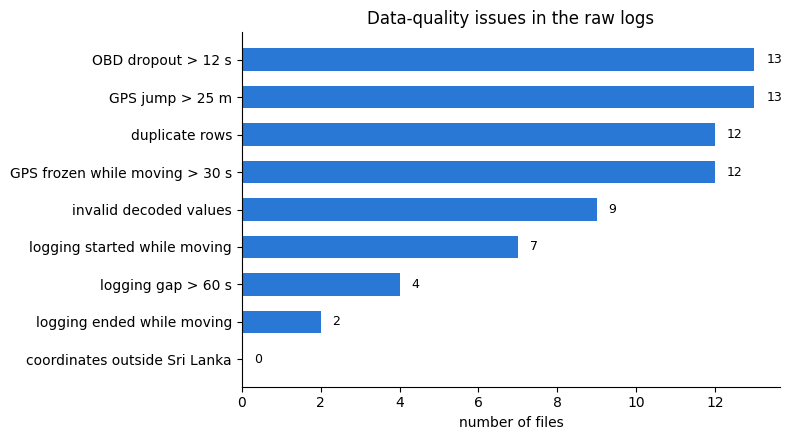

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(issue_counts.index, issue_counts.values, color=COLORS["bar"], height=0.6)
for y, v in enumerate(issue_counts.values):
    ax.text(v + 0.3, y, str(int(v)), va="center", fontsize=9)
ax.set(xlabel="number of files", title="Data-quality issues in the raw logs")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "quality_issues.png", dpi=150)
plt.show()

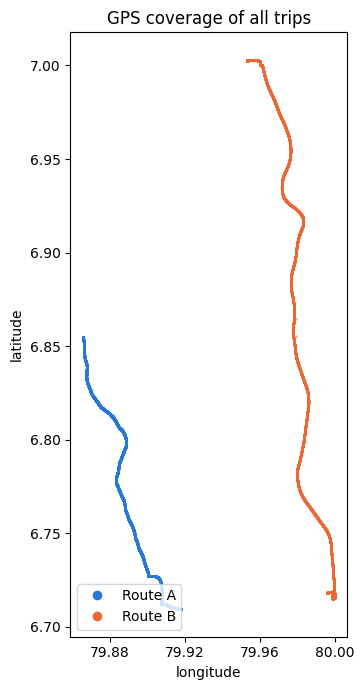

In [11]:
fig, ax = plt.subplots(figsize=(6, 7))
for _, row in files.iterrows():
    df = load_carscanner(row["path"])
    route = inventory.loc[inventory["file"] == row["file"], "route_hint"].iloc[0]
    g = df[[COL["lat"], COL["lon"]]].dropna().iloc[::5]          # every 5th point is enough for a map
    ax.plot(g[COL["lon"]], g[COL["lat"]], ".", ms=0.8, alpha=0.4, color=COLORS[route])
for k in ("Route A", "Route B"):
    ax.plot([], [], "o", color=COLORS[k], label=k)
ax.set_aspect("equal")
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.set(xlabel="longitude", ylabel="latitude", title="GPS coverage of all trips")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(OUT_DIR / "gps_coverage.png", dpi=150)
plt.show()

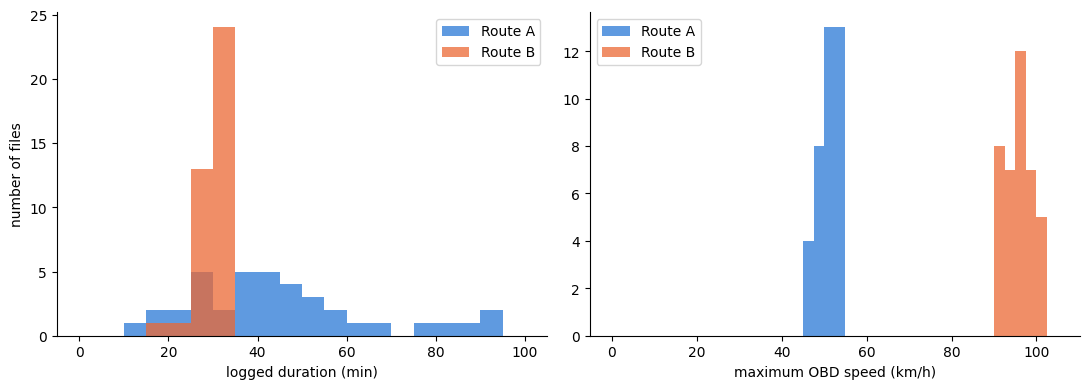

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dur_bins = np.arange(0, inventory["duration_min"].max() + 10, 5)
spd_bins = np.arange(0, inventory["max_speed_kmh"].max() + 5, 2.5)
for k in ("Route A", "Route B"):
    sub = inventory[inventory["route_hint"] == k]
    axes[0].hist(sub["duration_min"], bins=dur_bins, color=COLORS[k], alpha=0.75, label=k)
    axes[1].hist(sub["max_speed_kmh"], bins=spd_bins, color=COLORS[k], alpha=0.75, label=k)
axes[0].set(xlabel="logged duration (min)", ylabel="number of files")
axes[1].set(xlabel="maximum OBD speed (km/h)")
for ax in axes:
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "duration_and_max_speed.png", dpi=150)
plt.show()

In [13]:
print("STAGE 1 – RAW DATA INVENTORY: KEY FINDINGS")
print("-" * 60)
print(f"Files: {len(inventory)}  |  {summary['total logged time (h)']} h  |  {summary['total distance (km)']} km")
for k, row in by_route.iterrows():
    print(f"  {k:8s}: {row['files']:.0f} files, {row['hours']} h, {row['km']:.0f} km, "
          f"median lon {row['median_lon']}, {row['time_over_80kmh_pct']}% of time > 80 km/h")
print(f"OBD speed sampled every ~{inventory['speed_interval_s'].median():.1f} s; "
      f"GPS every ~{inventory['gps_interval_s'].median():.1f} s")
ev = param_table.loc[[COL['current'], COL['voltage'], COL['soc'], COL['power']], "available_in_%_of_files"]
print("EV parameters available (% of files):",
      ", ".join(f"{k.split(']')[-1].strip()} {v:.0f}%" for k, v in ev.items()))
print(f"Files with at least one issue: {(flags['n_issues'] > 0).sum()} of {len(flags)}")
for name, n in issue_counts[issue_counts > 0].sort_values(ascending=False).items():
    print(f"  - {name}: {n} files")
print("Route hints are from GPS position only; environment labels are assigned and verified in Stage 5.")

STAGE 1 – RAW DATA INVENTORY: KEY FINDINGS
------------------------------------------------------------
Files: 77  |  47.7 h  |  1933.6 km
  Route A : 38 files, 28.4 h, 587 km, median lon 79.89, 0.0% of time > 80 km/h
  Route B : 39 files, 19.3 h, 1347 km, median lon 79.98, 69.4% of time > 80 km/h
OBD speed sampled every ~3.7 s; GPS every ~1.0 s
EV parameters available (% of files): Battery total current (A) 100%, Battery total voltage (V) 100%, HV Battery Pack Current Nominal SoC (%) 100%, HV EV Battery Power (kW) 100%
Files with at least one issue: 52 of 77
  - GPS jump > 25 m: 13 files
  - OBD dropout > 12 s: 13 files
  - GPS frozen while moving > 30 s: 12 files
  - duplicate rows: 12 files
  - invalid decoded values: 9 files
  - logging started while moving: 7 files
  - logging gap > 60 s: 4 files
  - logging ended while moving: 2 files
Route hints are from GPS position only; environment labels are assigned and verified in Stage 5.


In [14]:
import folium
from folium import plugins
import branca.colormap as cm


def add_base_layers(m):
    """Street map (CARTO, OpenStreetMap data) + satellite (Esri). Both work inside Colab."""
    folium.TileLayer(
        tiles="https://{s}.basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}{r}.png",
        attr="&copy; OpenStreetMap contributors &copy; CARTO",
        name="Street map", subdomains="abcd", max_zoom=20,
    ).add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri World Imagery", name="Satellite",
    ).add_to(m)


m = folium.Map(location=[6.86, 79.93], zoom_start=11, tiles=None)
add_base_layers(m)

layers = {k: folium.FeatureGroup(name=f"{k} ({(inventory['route_hint'] == k).sum()} trips)")
          for k in ("Route A", "Route B")}

for _, row in files.iterrows():
    info = inventory.loc[inventory["file"] == row["file"]].iloc[0]
    df = load_carscanner(row["path"])
    g = gps_fixes(df).iloc[::3]                                    # every 3rd fix keeps the map light
    folium.PolyLine(
        g[[COL["lat"], COL["lon"]]].values.tolist(),
        color=COLORS[info["route_hint"]], weight=2, opacity=0.5,
        tooltip=(f"{info['trip_id']} | {info['start']:%Y-%m-%d %H:%M} | "
                 f"{info['distance_km']} km | max {info['max_speed_kmh']} km/h"),
    ).add_to(layers[info["route_hint"]])

for fg in layers.values():
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds(m.get_bounds())
m.save(str(OUT_DIR / "map_all_trips.html"))     # optional: open in any browser during the viva
m

In [15]:
TRIP = "T009"                                      # <-- any trip_id from the inventory

row = files.loc[files["trip_id"] == TRIP].iloc[0]
df = load_carscanner(row["path"])
one_s = (df[["timestamp", COL["lat"], COL["lon"], COL["speed"]]]
         .assign(**{COL["speed"]: df[COL["speed"]].where(df[COL["speed"]] < CFG["max_valid_speed_kmh"])})
         .set_index("timestamp").resample("1s").last().ffill().dropna())
pts = one_s[[COL["lat"], COL["lon"]]].values.tolist()
spd = one_s[COL["speed"]].values

colormap = cm.LinearColormap(["#d7191c", "#fdae61", "#a6d96a", "#1a9641"],
                             vmin=0, vmax=max(60, spd.max()), caption="OBD speed (km/h)")

m2 = folium.Map(location=pts[len(pts) // 2], zoom_start=12, tiles=None)
add_base_layers(m2)
folium.ColorLine(positions=pts, colors=spd[:-1], colormap=colormap, weight=5).add_to(m2)
colormap.add_to(m2)

folium.Marker(pts[0], tooltip=f"Start {one_s.index[0]:%H:%M:%S}",
              icon=folium.Icon(color="green", icon="play")).add_to(m2)
folium.Marker(pts[-1], tooltip=f"End {one_s.index[-1]:%H:%M:%S}",
              icon=folium.Icon(color="red", icon="stop")).add_to(m2)

# stops of 10 s or longer (signals, junctions, toll plazas)
stopped = one_s[COL["speed"]] < 1
block = (stopped != stopped.shift()).cumsum()
for _, s in one_s[stopped].groupby(block[stopped]):
    if len(s) >= 10:
        folium.CircleMarker(s[[COL["lat"], COL["lon"]]].iloc[0].tolist(), radius=6, color="black",
                            fill=True, fill_color="white",
                            tooltip=f"Stop {len(s)} s at {s.index[0]:%H:%M:%S}").add_to(m2)

folium.LayerControl().add_to(m2)
m2.fit_bounds([one_s[[COL["lat"], COL["lon"]]].min().tolist(),
               one_s[[COL["lat"], COL["lon"]]].max().tolist()])
m2.save(str(OUT_DIR / f"map_{TRIP}_speed.html"))
m2

In [16]:
stop_points = []
for _, row in files.iterrows():
    df = load_carscanner(row["path"])
    s = (df[["timestamp", COL["lat"], COL["lon"], COL["speed"]]]
         .set_index("timestamp").resample("1s").last().ffill().dropna())
    stop_points += s.loc[s[COL["speed"]] < 1, [COL["lat"], COL["lon"]]].values.tolist()

m3 = folium.Map(location=[6.86, 79.93], zoom_start=11, tiles=None)
add_base_layers(m3)
plugins.HeatMap(stop_points, radius=9, blur=12, min_opacity=0.3, name="Stop locations").add_to(m3)
folium.LayerControl().add_to(m3)
print(f"{len(stop_points)} stopped seconds plotted")
m3.save(str(OUT_DIR / "map_stop_heatmap.html"))
m3

20486 stopped seconds plotted


In [19]:
TRIP = "T066"                                      # <-- any trip_id from the inventory

row = files.loc[files["trip_id"] == TRIP].iloc[0]
df = load_carscanner(row["path"])
trk = (df[["timestamp", COL["lat"], COL["lon"], COL["speed"]]]
       .set_index("timestamp").resample("5s").last().ffill().dropna())

features = [{
    "type": "Feature",
    "geometry": {"type": "Point", "coordinates": [r[COL["lon"]], r[COL["lat"]]]},
    "properties": {"time": t.isoformat(),
                   "popup": f"{t:%H:%M:%S}  {r[COL['speed']]:.0f} km/h",
                   "icon": "circle",
                   "iconstyle": {"fillColor": "#eb6834", "fillOpacity": 0.9, "stroke": False, "radius": 6}},
} for t, r in trk.iterrows()]

m4 = folium.Map(location=trk[[COL["lat"], COL["lon"]]].mean().tolist(), zoom_start=12, tiles=None)
add_base_layers(m4)
folium.PolyLine(trk[[COL["lat"], COL["lon"]]].values.tolist(),
                color="#2a78d6", weight=3, opacity=0.6).add_to(m4)
plugins.TimestampedGeoJson({"type": "FeatureCollection", "features": features},
                           period="PT5S", duration="PT10S", add_last_point=True,
                           auto_play=False, loop=False, transition_time=200).add_to(m4)
folium.LayerControl().add_to(m4)
m4.save(str(OUT_DIR / f"map_{TRIP}_playback.html"))
m4